# Unemployment Analysis with Python
CodeAlpha Data Science Internship, Task 2. This notebook walks through the same pipeline the dashboard uses: clean, explore, test, interpret.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
from unemployment import data, analysis as an, report
report.plt.rcParams['figure.dpi'] = 90
%matplotlib inline

## 1. Load and clean
The raw files have leading spaces, blank rows, a duplicated `Region` header and swapped latitude/longitude columns. The loaders fix all of this.

In [2]:
df_area = data.load_state_area(); df_state = data.load_state()
print(df_area.shape, df_state.shape)
df_area.head()

(740, 9) (267, 10)


,state,date,frequency,unemployment_rate,employed,labour_participation_rate,area,macro_region,labour_force
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,South,1.245370e+07
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,South,1.212572e+07
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,South,1.255762e+07
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,South,1.270758e+07
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,South,1.292498e+07


In [3]:
pd.Series(data.data_quality_report(df_area, df_state))

state_area_rows                                    740
state_area_period             (2019-05-31, 2020-06-30)
state_rows                                         267
state_period                  (2020-01-31, 2020-10-31)
states_in_area_file                                 28
states_in_state_file                                27
overlap_rows                                       158
overlap_median_abs_diff_pp                    0.004527
overlap_share_within_0_5pp                    0.797468
missing_values                                       0
dtype: object

## 2. One continuous state-level panel (May 2019 - Oct 2020)

In [4]:
panel = data.build_panel(df_area, df_state)
print(panel.shape, panel['state'].nunique(), 'states')
panel.describe().round(2)

(490, 8) 28 states


,date,unemployment_rate,employed,labour_force,labour_participation_rate
count,490,490.00,490.00,490.00,490.00
mean,2020-02-11 23:15:55.102040,10.76,14121963.49,15561191.36,42.92
min,2019-05-31 00:00:00,0.00,89450.00,93969.95,16.77
25%,2019-09-30 00:00:00,4.67,2718174.75,2968429.15,38.49
50%,2020-01-31 00:00:00,8.13,9736205.00,10683420.82,41.58
75%,2020-06-30 00:00:00,14.36,22287205.75,23838698.18,45.45
max,2020-10-31 00:00:00,75.85,59433759.00,64893010.45,69.69
std,NaN,9.30,13626350.71,14811762.15,7.61


## 3. National trend and COVID-19 phases

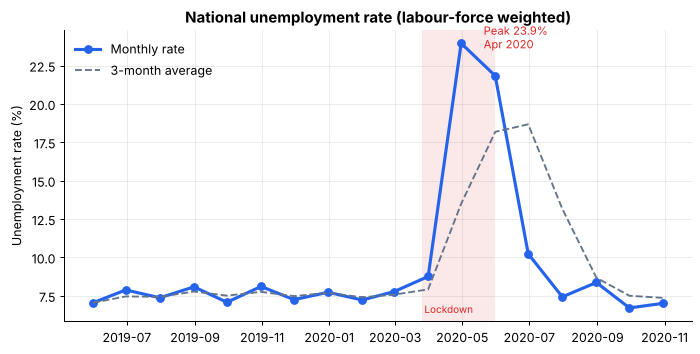

In [5]:
nat = an.national_trend(panel)
report.fig_national_trend(nat, report.Path('.')); 
from IPython.display import Image; Image('01_national_trend.png')

In [6]:
an.phase_summary(panel)

,phase,avg_rate,min_rate,max_rate,months,label
0,Pre-COVID,7.55,7.04,8.11,10,Pre-COVID (before Mar 2020)
1,Onset,8.76,8.76,8.76,1,Onset (Mar 2020)
2,Lockdown,22.89,21.83,23.95,2,Lockdown (Apr-May 2020)
3,Recovery,7.95,6.71,10.23,5,Recovery (Jun-Oct 2020)


## 4. Which states were hit hardest?

In [7]:
impact = an.covid_impact_by_state(panel)
impact.head(10)

,state,baseline_rate,peak_rate,peak_month,latest_rate,latest_month,macro_region,increase_pp,latest_vs_baseline_pp,recovered_share
0,Puducherry,1.75,75.85,2020-04-30,6.18,2020-10-31,South,74.10,4.43,0.94
1,Jharkhand,11.82,59.23,2020-05-31,11.80,2020-10-31,East,47.41,-0.02,1.00
2,Tamil Nadu,2.78,49.83,2020-04-30,2.16,2020-10-31,South,47.05,-0.62,1.00
3,Bihar,11.45,46.64,2020-04-30,9.82,2020-10-31,East,35.19,-1.63,1.00
4,Delhi,15.03,42.27,2020-05-31,6.27,2020-10-31,North,27.24,-8.76,1.00
5,Karnataka,3.22,29.84,2020-04-30,1.58,2020-10-31,South,26.62,-1.64,1.00
6,Haryana,22.59,43.22,2020-04-30,27.31,2020-10-31,North,20.63,4.72,0.77
7,Odisha,3.73,23.76,2020-04-30,2.18,2020-10-31,East,20.03,-1.55,1.00
8,Sikkim,6.04,24.51,2020-05-31,0.88,2020-10-31,Northeast,18.47,-5.16,1.00
9,Punjab,10.52,28.33,2020-05-31,9.88,2020-10-31,North,17.81,-0.64,1.00


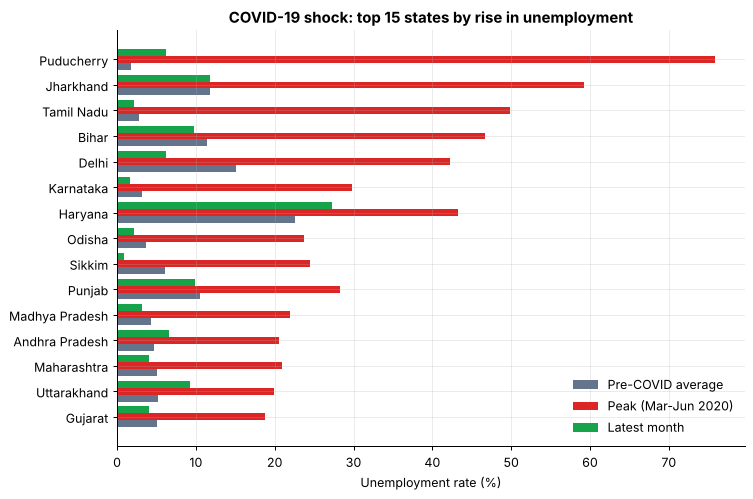

In [8]:
report.fig_state_impact(impact, report.Path('.')); Image('03_state_impact.png')

## 5. Is the lockdown effect statistically significant?

In [9]:
an.covid_significance(panel)

{'pre_mean': 9.037331204712578,
 'lockdown_mean': 22.74981132075472,
 'difference_pp': 13.712480116042142,
 'welch_t': 6.1189096813293835,
 'welch_p': 9.924600420392396e-08,
 'mannwhitney_p': 6.505697091081508e-13,
 'cohens_d': 1.112877597915056,
 'n_pre': 275,
 'n_lockdown': 53}

## 6. Urban vs rural

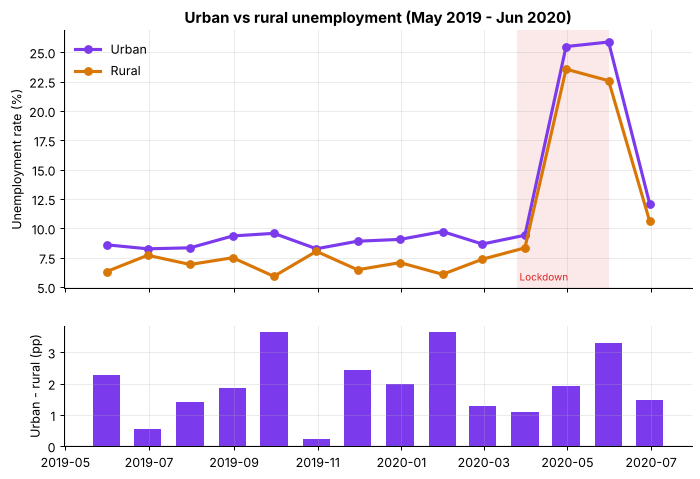

In [10]:
ur = an.urban_rural_trend(df_area)
report.fig_urban_rural(ur, report.Path('.')); Image('06_urban_rural.png')

## 7. Seasonality check
Only ~18 months exist, so decomposition is not possible. Months present in both years:

In [11]:
an.same_month_yoy(panel)

,month,rate_2019,rate_2020,change_pp
0,5,7.04,21.83,14.79
1,6,7.88,10.23,2.36
2,7,7.37,7.43,0.06
3,8,8.08,8.36,0.28
4,9,7.08,6.71,-0.37
5,10,8.11,7.01,-1.10


## 8. Insights

In [12]:
for line in an.generate_insights(panel, df_area): print('-', line)

- National unemployment averaged 7.6% before COVID-19, jumped to a peak of 23.9% in April 2020, and was 7.0% by October 2020.
- The lockdown effect is statistically significant: state-month rates were on average 13.7 percentage points higher in Apr-May 2020 than before COVID (Welch p = 9.9e-08, Cohen's d = 1.11).
- The largest state-level shocks (baseline to peak) were Puducherry (+74.1 pp), Jharkhand (+47.4 pp) and Tamil Nadu (+47.0 pp).
- By October 2020, 18 of 27 states were back at or below their pre-COVID average rate.
- Employment fell furthest in Puducherry (76% fewer employed people at the lockdown trough than in Feb 2020).
- Urban areas ran +1.9 pp relative to rural areas before COVID; at the peak (April 2020) urban unemployment was 25.5% vs 23.6% rural.
- In the latest month the lowest-unemployment macro-region was South (3.1%) and the highest was North (11.5%).
- Puducherry had the most volatile series (std 21.1 pp, range 0.0%-75.8%).
- Across state-months, unemployment and 